We will play with different convolutions, transformations, and filters to get a sense of feeling what they do

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [5]:
def run_filters(img: np.ndarray):
  return [
        ("Original", img),
        ("Box Blur 10x10", cv2.blur(img, (10, 10))),
        ("Gaussian Blur 9x9", cv2.GaussianBlur(img, (9, 9), sigmaX=2.5)),
        ("Median Blur 9", cv2.medianBlur(img, 9)),
    ]

In [6]:
def run_convs(img: np.ndarray):
  sharpen = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], dtype=np.float32)
  emboss = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=np.float32)
  edge = np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=np.float32)

  return [
        ("Original", img),
        ("Sharpen Kernel", cv2.filter2D(img, ddepth=-1, kernel=sharpen)),
        ("Emboss Kernel", cv2.filter2D(img, ddepth=-1, kernel=emboss)),
        ("Edge Kernel", cv2.filter2D(img, ddepth=-1, kernel=edge)),
    ]

In [7]:
def run_edge(img: np.ndarray):
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
  sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
  sobel_mag = cv2.magnitude(sobel_x, sobel_y)
  sobel_mag = cv2.convertScaleAbs(sobel_mag)
  lap = cv2.convertScaleAbs(cv2.Laplacian(gray, cv2.CV_64F, ksize=3))
  canny_low = cv2.Canny(gray, 30, 100)
  canny_high = cv2.Canny(gray, 80, 180)

  return [
        ("Gray", gray),
        ("Sobel Magnitude", sobel_mag),
        ("Laplacian", lap),
        ("Canny 30/100", canny_low),
        ("Canny 80/180", canny_high),
    ]

In [8]:
def run_transformations(img: np.ndarray):
  h, w = img.shape[:2]
  small = cv2.resize(img, (w // 2, h // 2), interpolation=cv2.INTER_AREA)

  rot_mat = cv2.getRotationMatrix2D((w / 2, h / 2), 45, 1.0)
  rotated = cv2.warpAffine(img, rot_mat, (w, h), flags=cv2.INTER_LINEAR)

  return [
        ("Original", img),
        ("Rotate 45 deg", rotated),
    ]


In [9]:
def load_image(image_path: str):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")
    return img


In [10]:
def plot_images(images_data, title_category=""):
    num_images = len(images_data)
    cols = 3
    rows = (num_images + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
    if num_images == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for i, (title, img) in enumerate(images_data):
        ax = axes[i]
        if len(img.shape) == 2 or img.shape[2] == 1:
            ax.imshow(img, cmap='gray')
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{title_category}: {title}")
        ax.axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

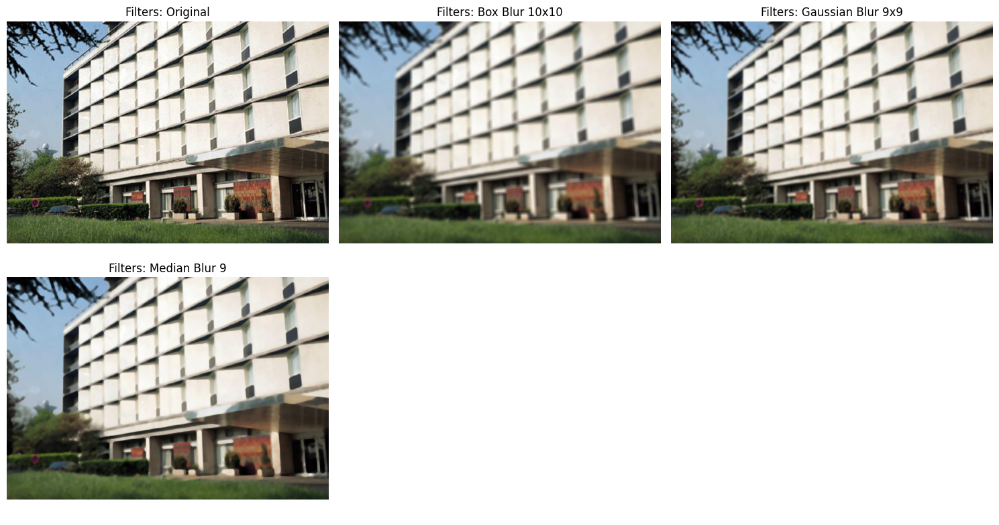

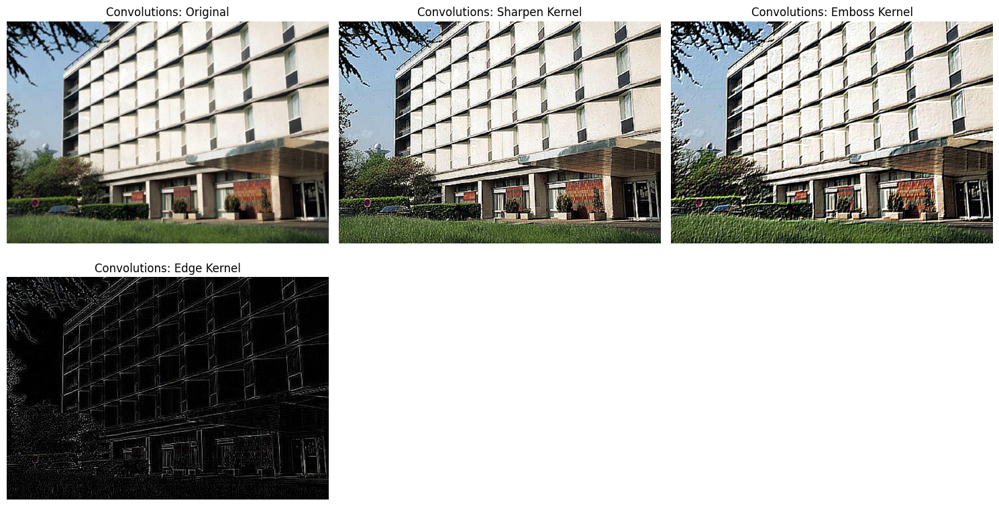

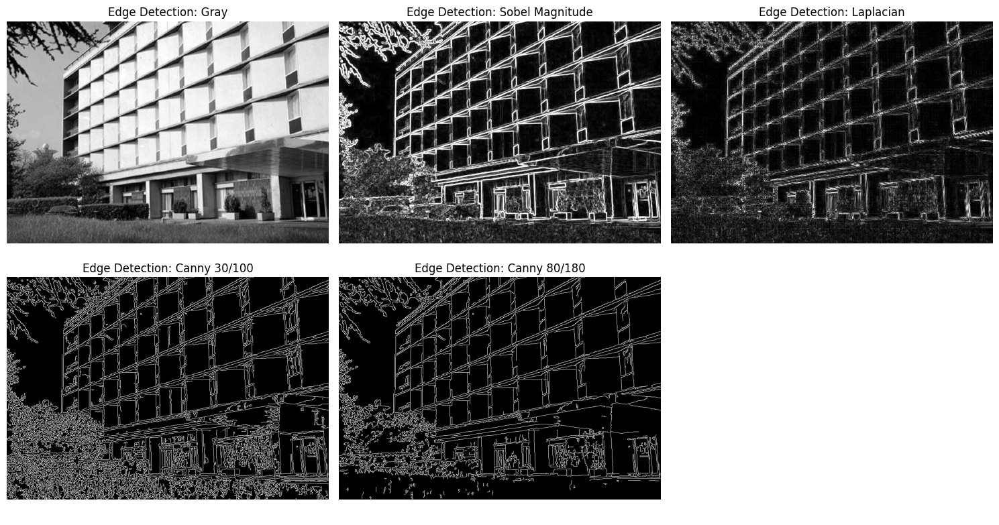

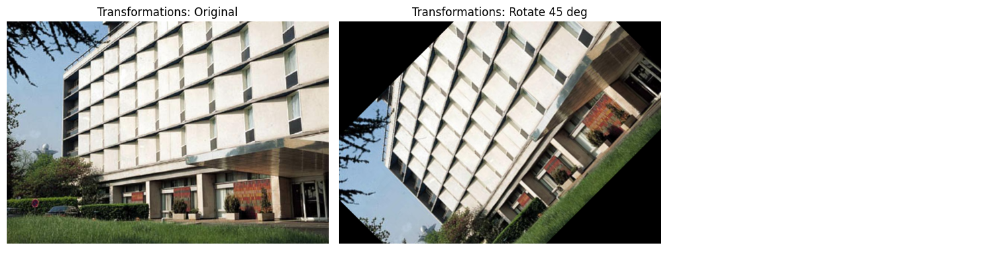

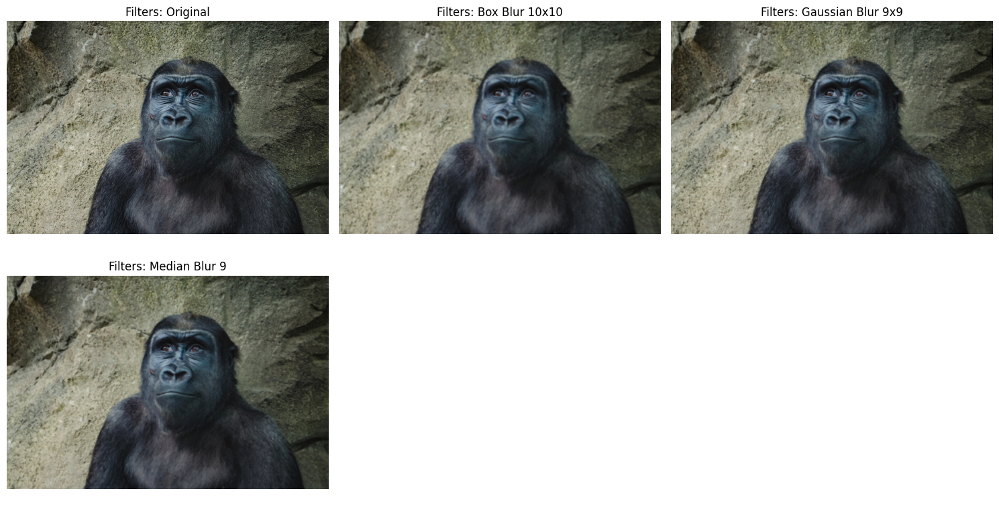

...

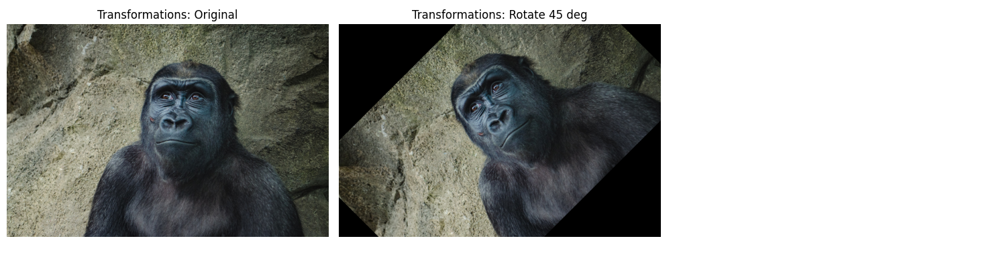

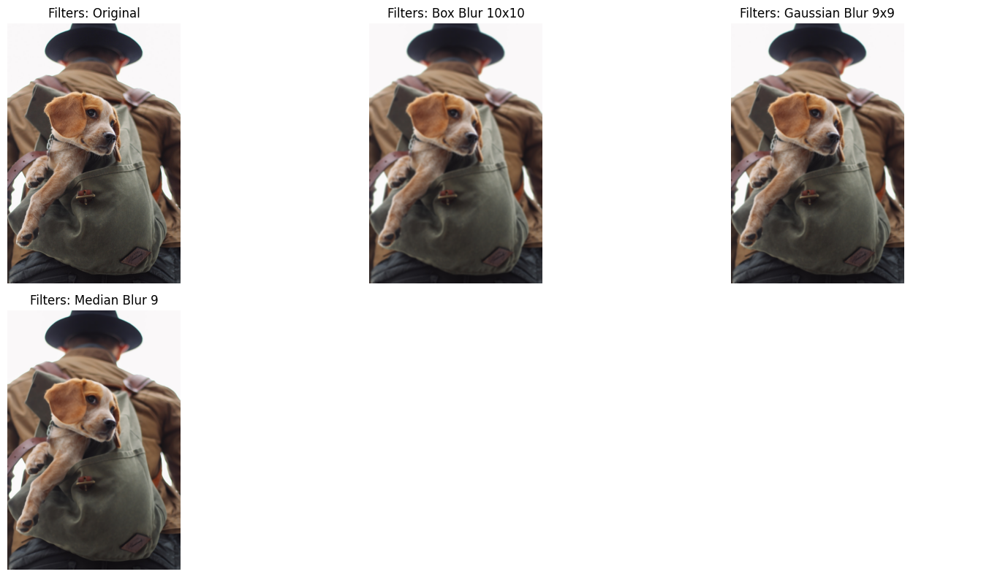

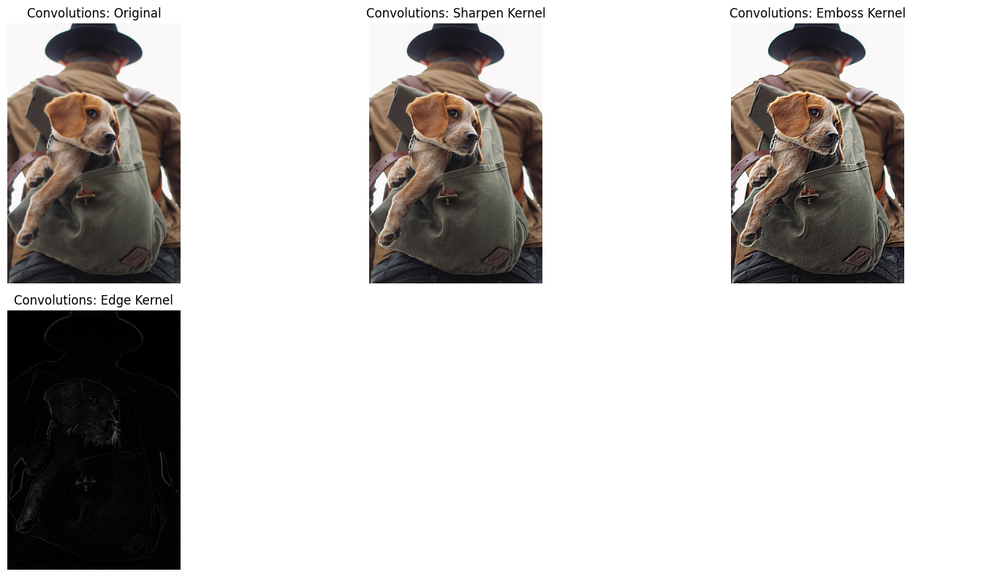

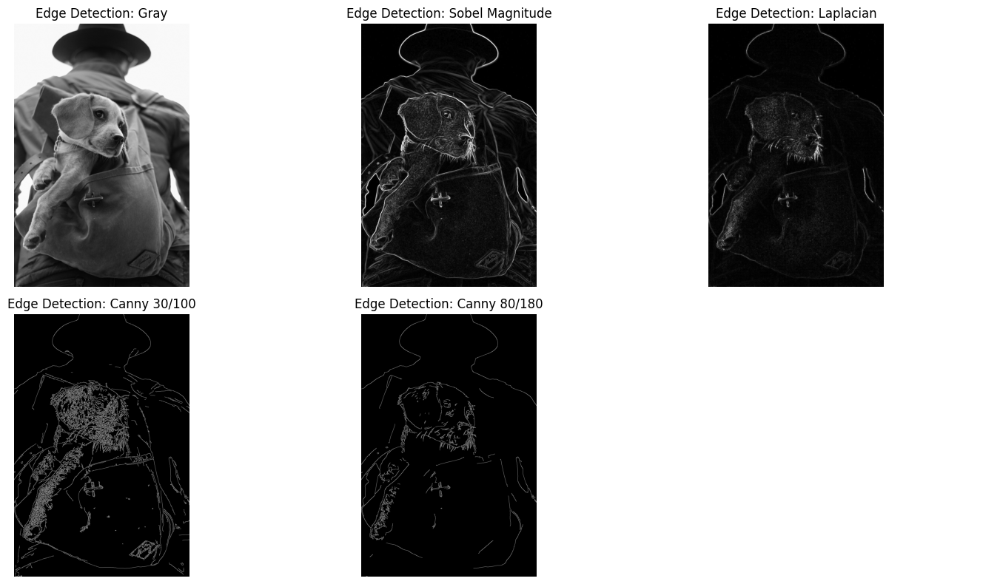

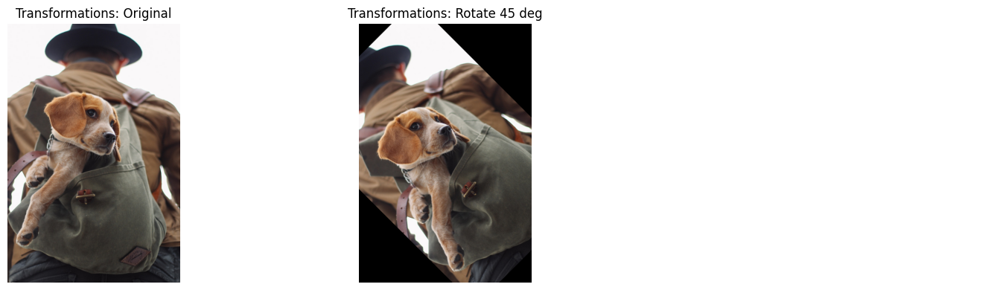

In [12]:
img_paths = ['building.jpg', 'gorilla.jpg', 'dog_backpack.jpg']
for img_path in img_paths:
    img = load_image(img_path)

    filters = run_filters(img)
    plot_images(filters, title_category="Filters")

    convs = run_convs(img)
    plot_images(convs, title_category="Convolutions")

    edge = run_edge(img)
    plot_images(edge, title_category="Edge Detection")

    transformations = run_transformations(img)
    plot_images(transformations, title_category="Transformations")

These are standard classical image manipulations (blurring, sharpening, and transformations) and edge detectors technique performed on various images: a building, a gorilla, and a dog.